# 04. Pencarian semantik (Fase 4)

**Tujuan:** menemukan lowongan yang *bermakna sama* dengan kueri walaupun katanya berbeda.

**Yang dipelajari:** embedding, cosine similarity, masalah *vocabulary mismatch*, dan cara memakai SBERT di komputermu.

**Penting:** notebook ini memakai `SemanticRetriever(backend="auto")`. Bila `sentence-transformers` terpasang dan model bisa diunduh,
ia memakai **SBERT**. Bila tidak, ia jatuh ke **LSA** (TF-IDF + SVD), pendekatan semantik klasik yang tidak butuh unduhan.
Sel bagian 2 menampilkan backend mana yang sedang dipakai, dan angka di bawahnya mengikuti backend itu.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # agar folder nlp_engine/ bisa diimpor
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from nlp_engine import *
from nlp_engine.preprocessing import normalize_text, tokenize, stem, STOPWORDS
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 160)
jobs, queries, qrels, ex = load_data("..")
job_ids = jobs.job_id.tolist()
print(f"{len(jobs)} lowongan, {len(queries)} kueri uji, {len(ex.names)} skill di kamus")

368 lowongan, 30 kueri uji, 56 skill di kamus


In [2]:
texts = job_text(jobs)
docs_tok = [preprocess(t, ex) for t in texts]
ix = InvertedIndex(docs_tok); bm25 = BM25(ix)

## 1. Kenapa BM25 saja tidak cukup
BM25 hanya mencocokkan kata. Coba kueri yang maknanya dekat dengan lowongan, tetapi kata-katanya jarang sama.

In [3]:
q = "mengelola kampanye promosi di internet supaya produk dikenal orang"
print("token kueri:", preprocess(q, ex))
top = bm25.search(preprocess(q, ex), 5)
print("BM25 menemukan:", jobs.loc[top, "job_title"].tolist() if top else "tidak ada hasil yang berarti")

token kueri: ['elola', 'kampanye', 'promosi', 'internet', 'supaya', 'produk', 'dikenal', 'orang']
BM25 menemukan: ['Video Editor (Fresh Graduate)', 'Junior Video Editor', 'Account Executive', 'Junior Digital Marketing Specialist', 'Digital Marketing Specialist']


## 2. Embedding dan cosine similarity
Embedding mengubah teks menjadi vektor sehingga teks yang bermakna dekat punya vektor yang arahnya mirip.
Kemiripan diukur dengan **cosine similarity** (1 = searah, 0 = tidak berkaitan).

Untuk SBERT, kita menyuruh model membaca teks mentah. Untuk LSA, kita memberi teks yang sudah dipraproses.

In [4]:
sem = SemanticRetriever(backend="auto")
sem_inputs = texts if True else None
# SBERT paling baik dengan kalimat asli; LSA bekerja pada token hasil praproses
fit_texts = texts if sem.requested == "sbert" else [" ".join(t) for t in docs_tok]
sem.fit(fit_texts)
to_q = (lambda s: s) if sem.backend == "sbert" else (lambda s: " ".join(preprocess(s, ex)))
print("backend yang dipakai:", sem.backend, "|", sem.note or "SBERT aktif")
print("bentuk matriks embedding:", sem.doc_vecs.shape)

backend yang dipakai: lsa | SBERT tidak tersedia (ModuleNotFoundError); memakai LSA.
bentuk matriks embedding: (368, 64)


In [5]:
top = sem.search(to_q(q), 5)
jobs.loc[top, ["job_id", "job_title", "experience_level"]].assign(cosine=sem.scores(to_q(q))[top].round(3))

,job_id,job_title,experience_level,cosine
159,J0160,Digital Marketing Specialist,Junior,0.616
30,J0031,Junior Digital Marketing Specialist,Junior,0.603
91,J0092,Digital Marketing Specialist,Mid-level,0.596
36,J0037,Digital Marketing Specialist Associate,Entry Level,0.595
293,J0294,Junior Digital Marketing Specialist,Entry Level,0.573


## 3. Peta lowongan di ruang embedding
Proyeksi 2D (PCA) dari vektor tiap lowongan, diwarnai menurut bidang. Lowongan satu bidang cenderung mengelompok,
dan bidang yang berdekatan (data, bi, ml) saling berimpitan, sesuai harapan.

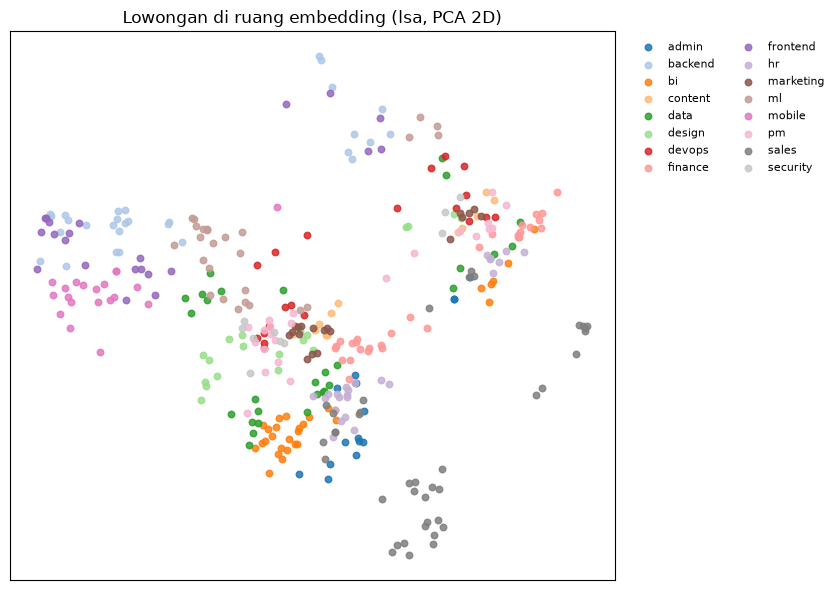

In [6]:
from sklearn.decomposition import PCA
xy = PCA(n_components=2, random_state=0).fit_transform(sem.doc_vecs)
fams = sorted(jobs.family.unique()); cmap = plt.get_cmap("tab20")
fig, ax = plt.subplots(figsize=(8.5, 6))
for i, f in enumerate(fams):
    m = (jobs.family == f).values
    ax.scatter(xy[m, 0], xy[m, 1], s=22, color=cmap(i), label=f, alpha=.85)
ax.legend(ncol=2, fontsize=8, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title(f"Lowongan di ruang embedding ({sem.backend}, PCA 2D)"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 4. Evaluasi E4 dan perbandingan dengan BM25

In [7]:
systems = {
    "E3 BM25":      lambda s: bm25.search(preprocess(s, ex), 50),
    f"E4 Semantik ({sem.backend})": lambda s: sem.search(to_q(s), 50),
}
res = {n: evaluate_system(f, queries, qrels, job_ids)[0] for n, f in systems.items()}
pd.DataFrame(res).T

,P@5,Recall@10,MRR@10,NDCG@5,NDCG@10
E3 BM25,0.880,0.827,0.944,0.844,0.797
E4 Semantik (lsa),0.913,0.860,0.933,0.855,0.824


### Kueri yang benar-benar diuntungkan oleh pencarian semantik

In [8]:
_, pq_b = evaluate_system(systems["E3 BM25"], queries, qrels, job_ids)
_, pq_s = evaluate_system(list(systems.values())[1], queries, qrels, job_ids)
d = pd.DataFrame({"kueri": queries.set_index("query_id")["query"].str[:60], "BM25": pq_b["NDCG@5"].round(2), "Semantik": pq_s["NDCG@5"].round(2)})
d["selisih"] = (d["Semantik"] - d["BM25"]).round(2)
d.sort_values("selisih", ascending=False).head(6)

,kueri,BM25,Semantik,selisih
query_id,,,,
Q23,menyusun roadmap produk dan menentukan prioritas fitur,0.68,1.00,0.32
Q18,"mengurus arsip, surat menyurat, dan jadwal pimpinan",0.68,1.00,0.32
Q01,"Saya menguasai Python, SQL, Pandas, dan visualisasi data. Sa",0.72,0.93,0.21
Q11,bisa jaringan komputer dan troubleshooting kantor,0.83,1.00,0.17
Q10,mengelola server dan deployment aplikasi di cloud,0.85,1.00,0.15
Q27,"I enjoy working with data and building reports, no formal ex",0.54,0.62,0.08


## 5. Memakai SBERT di komputermu
```bash
pip install sentence-transformers
```
Lalu di sel bagian 2 ganti `backend="auto"` menjadi `backend="sbert"`. Model bawaan modul ini adalah
`paraphrase-multilingual-MiniLM-L12-v2` (mendukung bahasa Indonesia). Model lain yang layak dicoba:
`intfloat/multilingual-e5-base` dan model Sentence-BERT khusus Indonesia dari Hugging Face.
Untuk SBERT, beri **teks asli** (bukan token), karena model dilatih pada kalimat utuh.

> **Latihan 7.** Jalankan notebook ini dengan `backend="sbert"` dan bandingkan dengan LSA pada tabel bagian 4 dan peta bagian 3.
> Catat kueri mana yang berubah paling banyak.

> **Latihan 8.** Simpan embedding lowongan ke berkas (`np.save`) supaya tidak dihitung ulang setiap kali. Ini langkah 6 pada
> alur dataset di rancangan proyek.

> **Latihan 9.** Coba `n_components` LSA yang berbeda (16, 32, 64, 128). Kapan hasilnya mulai turun, dan kenapa?